Assignment 3: Fetching and Processing Data from a Public REST API

1. Aim

To fetch data from a public REST API using Python, parse the JSON response, transform the retrieved data into a structured tabular format, perform basic data validation and preprocessing, and store the transformed data for further analysis.

2. Theory

A REST API (Representational State Transfer Application Programming Interface) is a web-based interface that allows applications to communicate with each other and exchange data over the internet. APIs commonly return data in JSON (JavaScript Object Notation) format, which is lightweight and easy to process.

In this experiment, Python is used to send a request to a public REST API and retrieve data in JSON format. The JSON response is then parsed and converted into a structured Pandas DataFrame. Basic data validation is performed by checking the shape, column names, data types, missing values, and duplicate records. The data is then preprocessed if required and stored in a CSV file for further analysis and visualization.

In [ ]:
import requests
import pandas as pd

In [ ]:
url = "https://jsonplaceholder.typicode.com/posts"

print("API URL:", url)

In [ ]:
response = requests.get(url)

print("Status Code:", response.status_code)

In [ ]:
data = response.json()

print(type(data))

In [ ]:
print("First 2 records:")
print(data[:2])

In [ ]:
df = pd.DataFrame(data)

print("Data converted into DataFrame successfully!")

display(df.head())

In [ ]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

In [ ]:
print("Column Names:")
print(df.columns.tolist())

In [ ]:
print("Data Types:")
print(df.dtypes)

In [ ]:
print("Missing Values:")
print(df.isnull().sum())

In [ ]:
print("Duplicate Records:", df.duplicated().sum())

In [ ]:
print("Total IDs:", df["id"].count())
print("Unique IDs:", df["id"].nunique())

In [ ]:
df = df.drop_duplicates()

print("Duplicates removed successfully.")
print("New number of rows:", len(df))

In [ ]:
print("Missing values after preprocessing:")
print(df.isnull().sum())

In [ ]:
df["body_length"] = df["body"].str.len()

display(df.head())

In [ ]:
print("Final Dataset Information:")
df.info()

In [ ]:
df.to_csv("API_Transformed_Data.csv", index=False)

print("Data successfully saved as API_Transformed_Data.csv")

In [ ]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

# Fetch data from API
url = "https://jsonplaceholder.typicode.com/posts"
response = requests.get(url)

# Convert JSON response to DataFrame
data = response.json()
df = pd.DataFrame(data)

# Count number of posts for each user
user_posts = df["userId"].value_counts().sort_index()

# Create bar chart
plt.figure(figsize=(8, 5))
plt.bar(user_posts.index, user_posts.values)

plt.title("Number of Posts per User")
plt.xlabel("User ID")
plt.ylabel("Number of Posts")

plt.show()

Conclusion

The experiment was successfully completed by fetching data from a public REST API using Python and parsing the JSON response. The retrieved data was converted into a structured Pandas DataFrame and validated by checking its dimensions, data types, missing values, duplicate records, and invalid entries. Basic preprocessing and data transformation were performed, and the final transformed dataset was successfully stored in CSV format for further analysis and visualization.

**Dynamic Visualization of Real-Time API Data**

Aim

To fetch current data continuously from a public REST API and develop a dynamic visualization that automatically updates as new data is retrieved from the API.

Theory

Real-time data visualization is the process of representing continuously updated data using graphical techniques. In this experiment, a public weather REST API is used to periodically retrieve current weather information in JSON format. Python is used to send repeated API requests, extract the required parameters, and update the visualization dynamically. Matplotlib is used to display the changing values as a graph. This demonstrates how live API data can be integrated with visualization tools to observe changes in data over time.

In [ ]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import time
from IPython.display import clear_output

In [ ]:
latitude = 18.5204
longitude = 73.8567

print("Location: Pune, Maharashtra")

In [ ]:
url = (
    f"https://api.open-meteo.com/v1/forecast?"
    f"latitude={latitude}&longitude={longitude}"
    f"&current=temperature_2m,relative_humidity_2m,wind_speed_10m"
)

print(url)

In [ ]:
response = requests.get(url)

print("Status Code:", response.status_code)

data = response.json()

print(data)

In [ ]:
current = data["current"]

temperature = current["temperature_2m"]
humidity = current["relative_humidity_2m"]
wind_speed = current["wind_speed_10m"]

print("Temperature:", temperature, "°C")
print("Humidity:", humidity, "%")
print("Wind Speed:", wind_speed, "km/h")

In [ ]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import time
from IPython.display import clear_output

latitude = 18.5204
longitude = 73.8567

url = (
    f"https://api.open-meteo.com/v1/forecast?"
    f"latitude={latitude}&longitude={longitude}"
    f"&current=temperature_2m,relative_humidity_2m,wind_speed_10m"
)

times = []
temperatures = []

print("Starting live temperature visualization...")
print("The graph will update every 10 seconds.")
print("Press the stop button in Colab to stop the experiment.")

for i in range(12):

    # Fetch current API data
    response = requests.get(url)
    data = response.json()

    # Extract current weather
    current = data["current"]

    temperature = current["temperature_2m"]
    humidity = current["relative_humidity_2m"]
    wind_speed = current["wind_speed_10m"]

    # Get API timestamp
    current_time = current["time"]

    # Store temperature
    times.append(current_time)
    temperatures.append(temperature)

    # Clear previous output
    clear_output(wait=True)

    # Display latest values
    print("LIVE WEATHER DATA - PUNE")
    print("--------------------------------")
    print("Time:", current_time)
    print("Temperature:", temperature, "°C")
    print("Humidity:", humidity, "%")
    print("Wind Speed:", wind_speed, "km/h")
    print("--------------------------------")
    print("Reading:", i + 1, "of 12")

    # Create graph
    plt.figure(figsize=(10, 5))

    plt.plot(
        times,
        temperatures,
        marker="o"
    )

    plt.title("Dynamic Temperature Visualization - Pune")
    plt.xlabel("API Reading Time")
    plt.ylabel("Temperature (°C)")
    plt.xticks(rotation=45)

    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # Wait before next API request
    time.sleep(10)

LIVE WEATHER DATA - PUNE
----------------------------
Time: 2026-08-17T06:30
Temperature: 25.2 °C
Humidity: 76 %
Wind Speed: 18.0 km/h


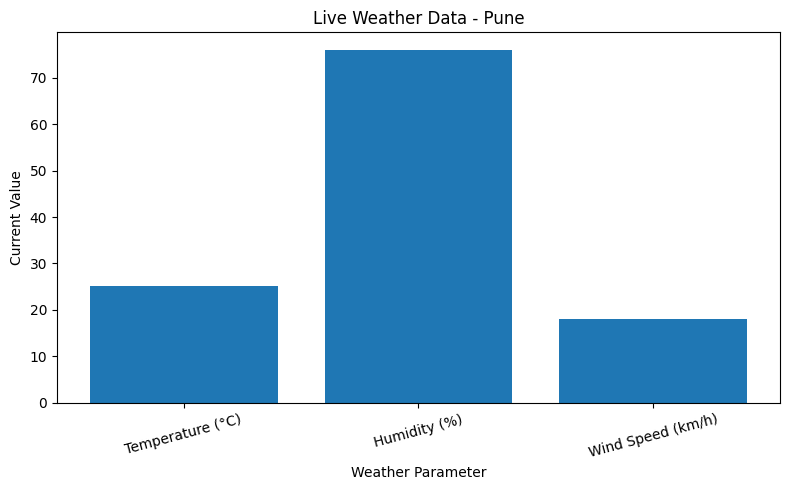

In [ ]:
import requests
import matplotlib.pyplot as plt
import time
from IPython.display import clear_output

latitude = 18.5204
longitude = 73.8567

url = (
    f"https://api.open-meteo.com/v1/forecast?"
    f"latitude={latitude}&longitude={longitude}"
    f"&current=temperature_2m,relative_humidity_2m,wind_speed_10m"
)

for i in range(12):

    # Fetch latest API data
    response = requests.get(url)
    data = response.json()

    current = data["current"]

    temperature = current["temperature_2m"]
    humidity = current["relative_humidity_2m"]
    wind_speed = current["wind_speed_10m"]
    current_time = current["time"]

    # Clear previous graph
    clear_output(wait=True)

    # Display current values
    print("LIVE WEATHER DATA - PUNE")
    print("----------------------------")
    print("Time:", current_time)
    print("Temperature:", temperature, "°C")
    print("Humidity:", humidity, "%")
    print("Wind Speed:", wind_speed, "km/h")

    # Create dynamic bar chart
    plt.figure(figsize=(8, 5))

    parameters = [
        "Temperature (°C)",
        "Humidity (%)",
        "Wind Speed (km/h)"
    ]

    values = [
        temperature,
        humidity,
        wind_speed
    ]

    plt.bar(parameters, values)

    plt.title("Live Weather Data - Pune")
    plt.xlabel("Weather Parameter")
    plt.ylabel("Current Value")

    plt.xticks(rotation=15)
    plt.tight_layout()

    plt.show()

    # Wait 10 seconds before fetching again
    time.sleep(10)

Conclusion  

The experiment was successfully completed by fetching current weather data from the Open-Meteo public REST API and processing the retrieved JSON data using Python. The temperature, humidity, and wind speed data were extracted and represented using a dynamically updating bar chart. The visualization was refreshed at regular intervals by repeatedly requesting updated API data, demonstrating how live API data can be integrated with dynamic data visualization to observe changes in real time.

**API Data Conversion**

Aim

To retrieve data from a public REST API, convert the JSON response into a structured Pandas DataFrame, store the transformed data in CSV format, and merge related data obtained from two different REST APIs using a common key.

Theory

A REST API (Representational State Transfer Application Programming Interface) enables applications to communicate and exchange data over the internet. The data returned by a REST API is commonly provided in JSON (JavaScript Object Notation) format.

In this experiment, data is retrieved from a public REST API using Python's requests library. The JSON response is parsed and converted into a structured Pandas DataFrame, which represents the data in tabular form with rows and columns. The DataFrame is then stored as a CSV (Comma-Separated Values) file using the to_csv() function. This process demonstrates how data obtained from an online API can be transformed into a commonly used tabular format for further analysis and visualization.

In [ ]:
import requests
import pandas as pd

In [ ]:
url = "https://jsonplaceholder.typicode.com/posts"

response = requests.get(url)

print("Status Code:", response.status_code)

In [ ]:
data = response.json()

print("Data Type:", type(data))

In [ ]:
df = pd.DataFrame(data)

print("Data converted into DataFrame successfully!")

display(df.head())

Check the DataFrame

In [ ]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

In [ ]:
df.to_csv("API_Data.csv", index=False)

print("Data successfully converted and saved as CSV!")

In [ ]:
csv_data = pd.read_csv("API_Data.csv")

print("CSV Data:")
display(csv_data.head())

 Conclusion

The experiment was successfully completed by retrieving data from a public REST API in JSON format, converting the response into a structured Pandas DataFrame, and storing the transformed data as a CSV file. This experiment demonstrated the process of converting API-based JSON data into a readable and accessible tabular format for further data analysis and visualization.

**Merge data from TWO APIs**

Aim

To retrieve related data from two different public REST APIs, identify a common key between the datasets, merge the retrieved data into a single structured DataFrame, and store the merged data in CSV format.

Theory

Data required for analysis is often distributed across multiple sources. Data integration is the process of combining data from different sources into a single dataset. When two datasets contain a common key or related attribute, they can be joined using operations such as merge in Pandas.

In this experiment, data is retrieved from two related public REST APIs. The first API provides user information, while the second API provides posts created by those users. The user ID acts as the common key between the two datasets. The retrieved JSON responses are converted into Pandas DataFrames and merged using the pd.merge() function. The resulting integrated dataset is then stored in CSV format. This demonstrates how data from multiple API sources can be combined into a unified dataset for further analysis.

Fetch Users API

In [ ]:
users_url = "https://jsonplaceholder.typicode.com/users"

users_response = requests.get(users_url)

print("Users API Status Code:", users_response.status_code)

users_data = users_response.json()

users_df = pd.DataFrame(users_data)

display(users_df.head())

Fetch Posts API

In [ ]:
posts_url = "https://jsonplaceholder.typicode.com/posts"

posts_response = requests.get(posts_url)

print("Posts API Status Code:", posts_response.status_code)

posts_data = posts_response.json()

posts_df = pd.DataFrame(posts_data)

display(posts_df.head())

Select useful columns

Use

In [ ]:
users_selected = users_df[
    ["id", "name", "username", "email"]
]

display(users_selected.head())

for posts:

In [ ]:
posts_selected = posts_df[
    ["userId", "id", "title", "body"]
]

display(posts_selected.head())

 Merge the two APIs

In [ ]:
merged_df = pd.merge(
    posts_selected,
    users_selected,
    left_on="userId",
    right_on="id",
    how="inner"
)

display(merged_df.head())

Clean the duplicate ID column

A better approach is to rename the user ID:

In [ ]:
users_selected = users_df[
    ["id", "name", "username", "email"]
].rename(columns={"id": "userId"})

Then merge

In [ ]:
merged_df = pd.merge(
    posts_selected,
    users_selected,
    on="userId",
    how="inner"
)

display(merged_df.head())

Check merged data

In [ ]:
print("Merged Dataset Shape:", merged_df.shape)

print("\nColumn Names:")
print(merged_df.columns.tolist())

print("\nMissing Values:")
print(merged_df.isnull().sum())

In [ ]:
merged_df.to_csv(
    "Merged_API_Data.csv",
    index=False
)

print("Merged API data successfully saved!")

In [ ]:
merged_df.to_csv("Merged_API_Data.csv", index=False)
final_data = pd.read_csv("Merged_API_Data.csv")

display(final_data.head())

Conclusion

The experiment was successfully completed by retrieving data from two related public REST APIs and converting the JSON responses into Pandas DataFrames. A common user ID was identified and used to merge the datasets into a single structured DataFrame. The integrated data was successfully stored in CSV format, demonstrating the process of combining information from multiple API sources for further data analysis and visualization.